# Projet Machine Learning : Prédiction du Prix des Diamants
**Dataset :** Diamonds Price Dataset – Kaggle


## 0. Configuration de l'Environnement et Importation des Bibliothèques

Nous importons les bibliothèques.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1. Exploration et Analyse des Données (EDA)

Dans cette étape, nous chargeons le jeu de données et analysons sa structure fondamentale :
* Examen avec `head()`, `shape`, `info()` et `describe()`.
* Identification des variables numériques et catégorielles.
* Analyse des valeurs manquantes, doublons et incohérences.
* Étude des distributions (histogrammes, boxplots).
* Analyse des corrélations et des relations avec la cible (`price`).
* Détection des valeurs aberrantes (*outliers*) via la méthode IQR.


In [ ]:
df = pd.read_csv('../data/diamonds.csv')
print(f"Dimensions du jeu de données : {df.shape}\n")
display(df.head())


Dimensions du jeu de données : (50000, 10)



,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [36]:
df.info()

display(df.describe())


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    50000 non-null  float64
 1   cut      50000 non-null  str    
 2   color    50000 non-null  str    
 3   clarity  50000 non-null  str    
 4   depth    50000 non-null  float64
 5   table    50000 non-null  float64
 6   price    50000 non-null  int64  
 7   x        50000 non-null  float64
 8   y        50000 non-null  float64
 9   z        50000 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.3 MB


,carat,depth,table,price,x,y,z
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,0.799444,61.753006,57.457830,3944.805440,5.734403,5.737956,3.541056
std,0.475173,1.431088,2.232092,3997.938105,1.123077,1.145579,0.707065
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,951.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2410.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5351.000000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


### Typologie des variables :
* **Cible ($y$) :** `price` (prix en dollars USD, de ~326 $ à ~18 823 $).
* **Variables numériques continues ($X_{num}$) :**
  * `carat`
  * `depth`
  * `table`
  * `x`, `y`, `z`
* **Variables catégorielles ordinales ($X_{ord}$) :**
  * `cut`
  * `color`
  * `clarity`


In [37]:
print("1. Valeurs manquantes par attribut :")
print(df.isnull().sum())

print(f"\n2. Nombre de doublons : {df.duplicated().sum()}")

zero_dims = df[(df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)]
print(f"\n3. Nombre de diamants avec dimensions nulles (x, y ou z == 0) : {len(zero_dims)}")


1. Valeurs manquantes par attribut :
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

2. Nombre de doublons : 126

3. Nombre de diamants avec dimensions nulles (x, y ou z == 0) : 17


### Distributions univariées et détection des outliers (IQR)
Visualisons les distributions avec histogrammes et boxplots, puis quantifions les outliers selon la méthode de l'intervalle interquartile ($[Q_1 - 1.5 \times IQR, Q_3 + 1.5 \times IQR]$).


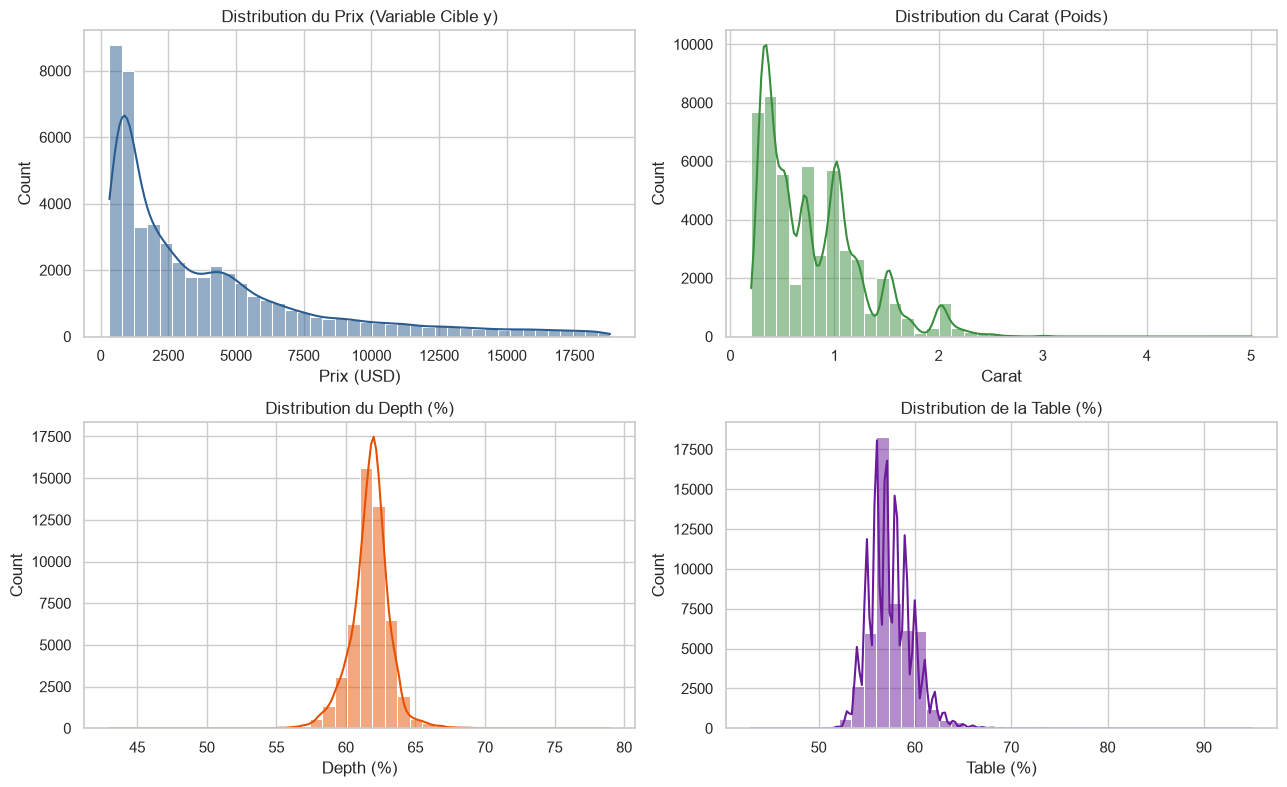

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(df['price'], kde=True, ax=axes[0, 0], color='#2b5c8f', bins=40)
axes[0, 0].set_title('Distribution du Prix (Variable Cible y)')
axes[0, 0].set_xlabel('Prix (USD)')

sns.histplot(df['carat'], kde=True, ax=axes[0, 1], color='#388e3c', bins=40)
axes[0, 1].set_title('Distribution du Carat (Poids)')
axes[0, 1].set_xlabel('Carat')

sns.histplot(df['depth'], kde=True, ax=axes[1, 0], color='#e65100', bins=40)
axes[1, 0].set_title('Distribution du Depth (%)')
axes[1, 0].set_xlabel('Depth (%)')

sns.histplot(df['table'], kde=True, ax=axes[1, 1], color='#6a1b9a', bins=40)
axes[1, 1].set_title('Distribution de la Table (%)')
axes[1, 1].set_xlabel('Table (%)')
plt.tight_layout()
plt.show()


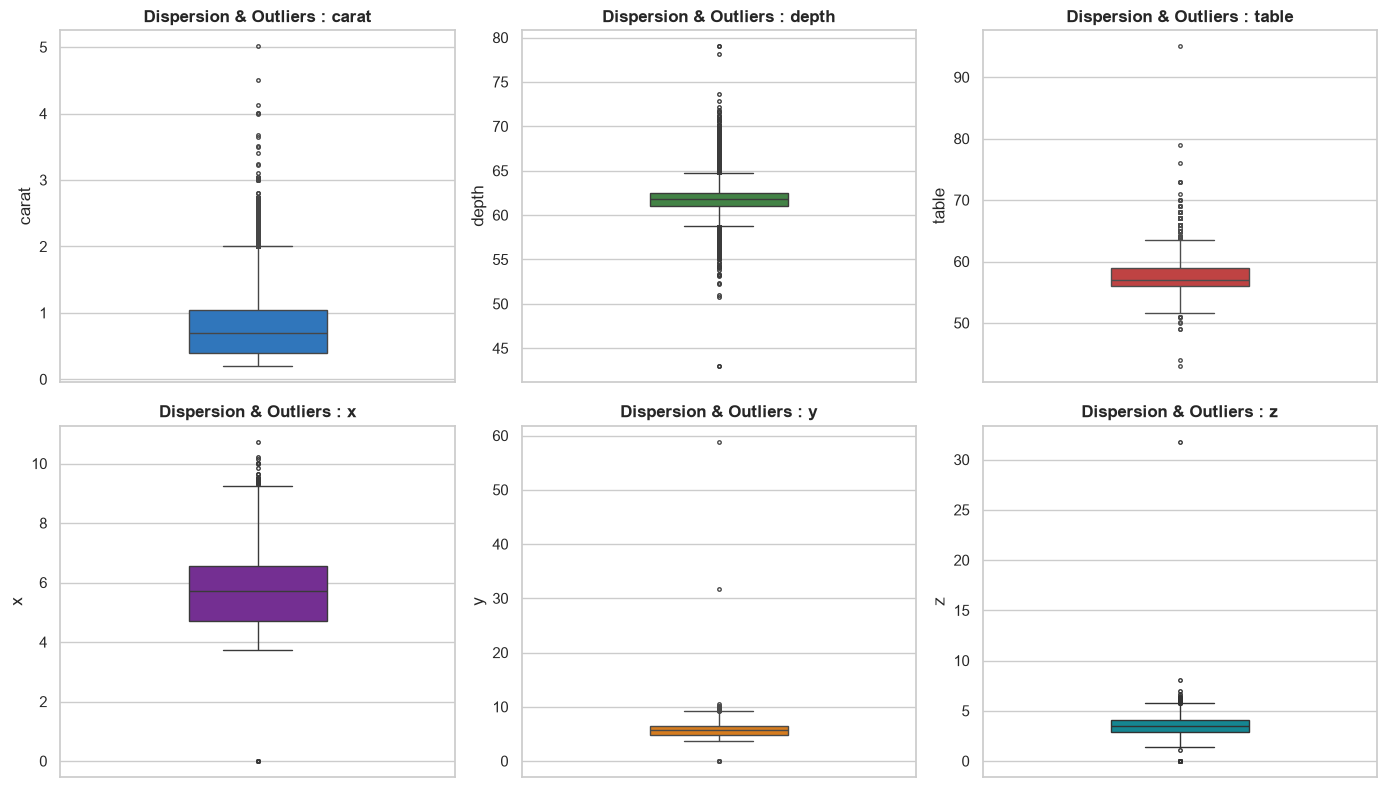

In [39]:
num_cols = ['carat', 'depth', 'table', 'x', 'y', 'z']
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
palette = ['#1976d2', '#388e3c', '#d32f2f', '#7b1fa2', '#f57c00', '#0097a7']
for i, col in enumerate(num_cols):
    ax = axes[i // 3, i % 3]
    sns.boxplot(y=df[col], ax=ax, color=palette[i], width=0.35, fliersize=2.5)
    ax.set_title(f'Dispersion & Outliers : {col}', fontweight='bold')
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()


In [40]:
print("Quantification des Outliers par la méthode IQR (Q1 - 1.5*IQR / Q3 + 1.5*IQR) :")
print("-" * 75)
for col in ['carat', 'depth', 'table', 'x', 'y', 'z', 'price']:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    n_out = len(df[(df[col] < lower_bound) | (df[col] > upper_bound)])
    pct_out = (n_out / len(df)) * 100
    print(f"{col:<8} | Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f} | Seuil=[{lower_bound:.2f}, {upper_bound:.2f}] | Outliers: {n_out:>5} ({pct_out:.2f}%)")


Quantification des Outliers par la méthode IQR (Q1 - 1.5*IQR / Q3 + 1.5*IQR) :
---------------------------------------------------------------------------
carat    | Q1=0.40, Q3=1.04, IQR=0.64 | Seuil=[-0.56, 2.00] | Outliers:  1770 (3.54%)
depth    | Q1=61.00, Q3=62.50, IQR=1.50 | Seuil=[58.75, 64.75] | Outliers:  2359 (4.72%)
table    | Q1=56.00, Q3=59.00, IQR=3.00 | Seuil=[51.50, 63.50] | Outliers:   558 (1.12%)
x        | Q1=4.71, Q3=6.54, IQR=1.83 | Seuil=[1.96, 9.29] | Outliers:    31 (0.06%)
y        | Q1=4.72, Q3=6.54, IQR=1.82 | Seuil=[1.99, 9.27] | Outliers:    28 (0.06%)
z        | Q1=2.91, Q3=4.04, IQR=1.13 | Seuil=[1.22, 5.73] | Outliers:    45 (0.09%)
price    | Q1=951.00, Q3=5351.00, IQR=4400.00 | Seuil=[-5649.00, 11951.00] | Outliers:  3264 (6.53%)


### Relations bivariées et corrélations
Analysons comment le prix varie en fonction du poids en carats et des attributs qualitatifs (`cut`, `color`, `clarity`).


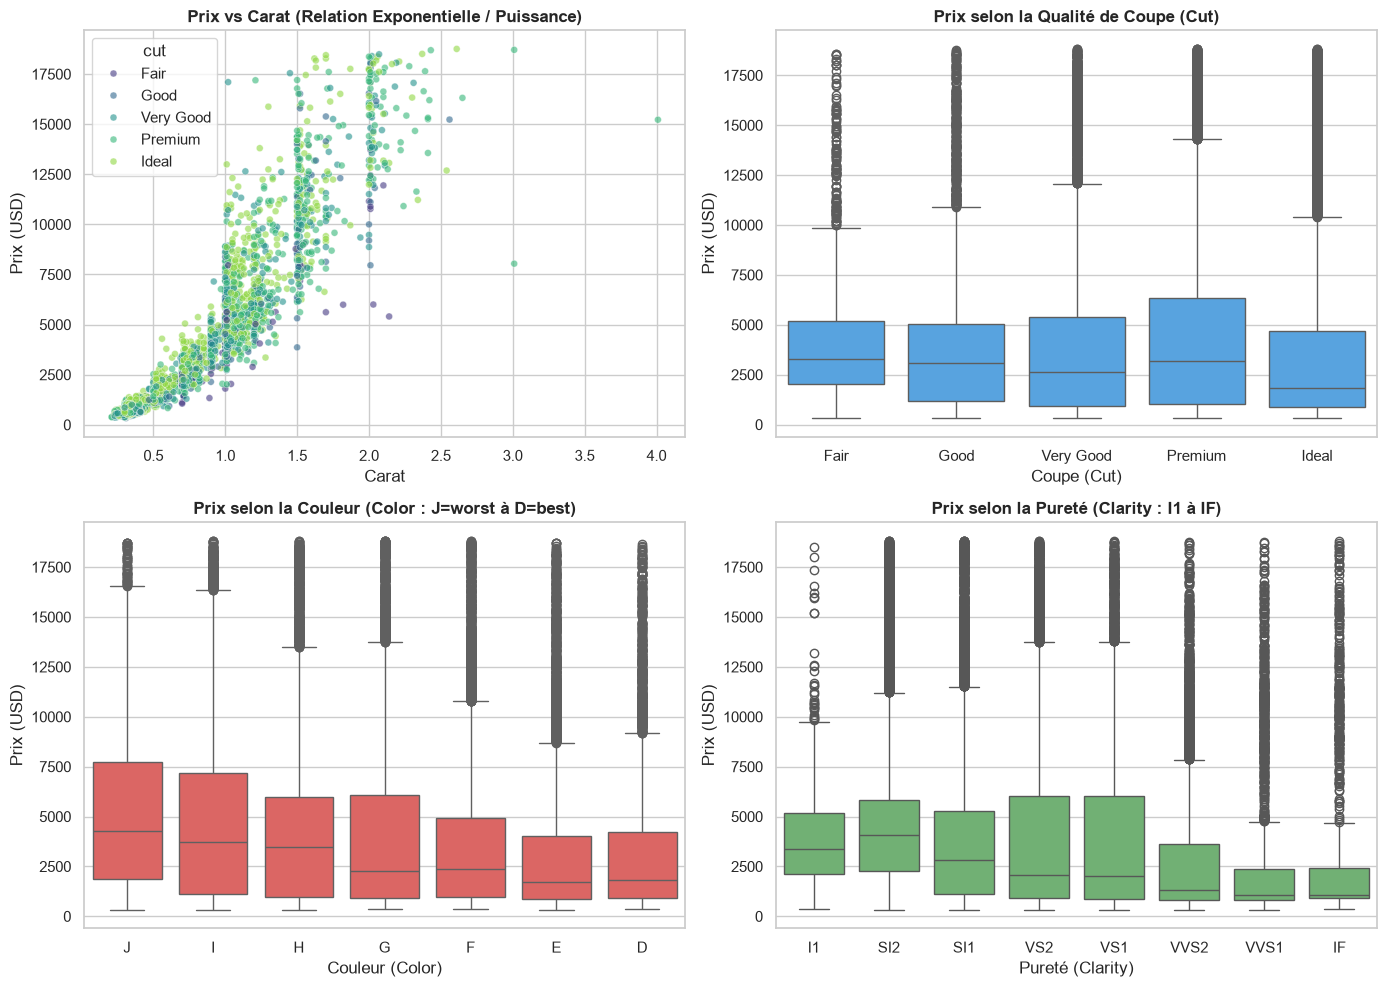

In [41]:
cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
color_order = ['J', 'I', 'H', 'G', 'F', 'E', 'D']
clarity_order = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sample_df = df.sample(n=3500, random_state=42)

sns.scatterplot(data=sample_df, x='carat', y='price', hue='cut', hue_order=cut_order,
                alpha=0.6, s=25, ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Prix vs Carat (Relation Exponentielle / Puissance)', fontweight='bold')
axes[0, 0].set_xlabel('Carat')
axes[0, 0].set_ylabel('Prix (USD)')

sns.boxplot(data=df, x='cut', y='price', order=cut_order, ax=axes[0, 1], color='#42a5f5')
axes[0, 1].set_title('Prix selon la Qualité de Coupe (Cut)', fontweight='bold')
axes[0, 1].set_xlabel('Coupe (Cut)')
axes[0, 1].set_ylabel('Prix (USD)')

sns.boxplot(data=df, x='color', y='price', order=color_order, ax=axes[1, 0], color='#ef5350')
axes[1, 0].set_title('Prix selon la Couleur (Color : J=worst à D=best)', fontweight='bold')
axes[1, 0].set_xlabel('Couleur (Color)')
axes[1, 0].set_ylabel('Prix (USD)')

sns.boxplot(data=df, x='clarity', y='price', order=clarity_order, ax=axes[1, 1], color='#66bb6a')
axes[1, 1].set_title('Prix selon la Pureté (Clarity : I1 à IF)', fontweight='bold')
axes[1, 1].set_xlabel('Pureté (Clarity)')
axes[1, 1].set_ylabel('Prix (USD)')

plt.tight_layout()
plt.show()


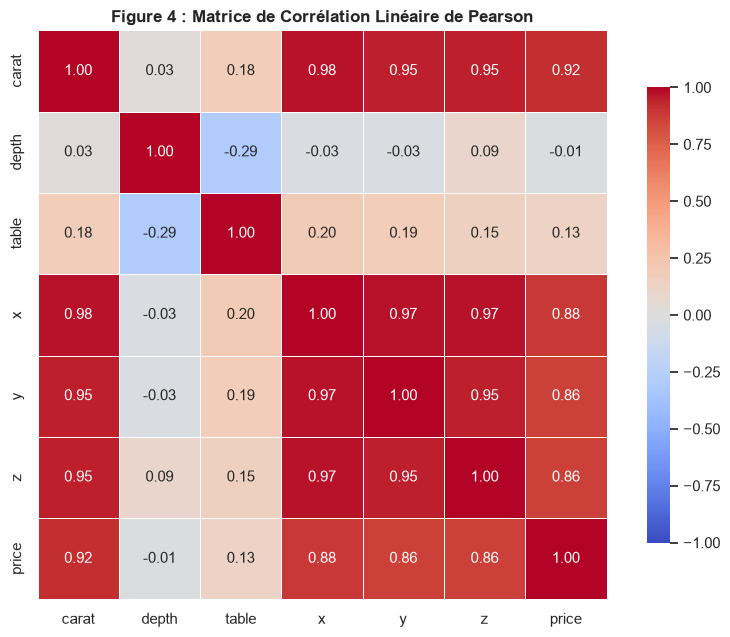

In [42]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
corr = df[['carat', 'depth', 'table', 'x', 'y', 'z', 'price']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Figure 4 : Matrice de Corrélation Linéaire de Pearson', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 2. Nettoyage des Données (Data Cleaning)

### Décisions de nettoyage argumentées :
1. **Suppression des 146 doublons stricts :** Des doublons exacts sur toutes les caractéristiques créent un sur-échantillonnage artificiel injustifié.
2. **Suppression des 20 diamants à dimensions nulles ($x \le 0, y \le 0, z \le 0$) :** Un objet tridimensionnel réel ne peut avoir une longueur ou une épaisseur nulle ; ce sont des erreurs manifestes de saisie.
3. **Suppression des dimensions physiques aberrantes :** Quelques valeurs de $y > 30$ mm ou $z > 30$ mm représentent des erreurs d'acquisition évidentes.


In [43]:
df_clean = df.copy()

n_dups_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()
print(f"1. Doublons supprimés : {n_dups_before} lignes.")

zeros_mask = (df_clean['x'] <= 0) | (df_clean['y'] <= 0) | (df_clean['z'] <= 0)
n_zeros = zeros_mask.sum()
df_clean = df_clean[~zeros_mask]
print(f"2. Diamants à dimensions nulles (x, y ou z <= 0) supprimés : {n_zeros} lignes.")

dim_outliers = (df_clean['y'] >= 30) | (df_clean['z'] >= 30) | (df_clean['z'] <= 1.5)
n_dim_outliers = dim_outliers.sum()
df_clean = df_clean[~dim_outliers]

print(f"\nForme avant nettoyage : {df.shape}")
print(f"Forme après nettoyage : {df_clean.shape}")
print(f"Nombre total de lignes retirées : {len(df) - len(df_clean)}")
print(f"Nombre de valeurs manquantes résiduelles : {df_clean.isnull().sum().sum()}")


1. Doublons supprimés : 126 lignes.
2. Diamants à dimensions nulles (x, y ou z <= 0) supprimés : 17 lignes.

Forme avant nettoyage : (50000, 10)
Forme après nettoyage : (49852, 10)
Nombre total de lignes retirées : 148
Nombre de valeurs manquantes résiduelles : 0


## 3. Préparation des Données

Nous définissons la cible $y$ (`price`) et la matrice des variables explicatives $X$. Nous catégorisons les variables selon leur nature mathématique :
* **Variables numériques ($X_{num}$) :** `['carat', 'depth', 'table', 'x', 'y', 'z']`
* **Variables ordinales ($X_{ord}$) :** `['cut', 'color', 'clarity']`.


In [44]:
target_col = 'price'
X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

numerical_features = ['carat', 'depth', 'table', 'x', 'y', 'z']
ordinal_features = ['cut', 'color', 'clarity']

print("Features numériques :", numerical_features)
print("Features ordinales :", ordinal_features)
print(f"Dimensions : X={X.shape}, y={y.shape}")


Features numériques : ['carat', 'depth', 'table', 'x', 'y', 'z']
Features ordinales : ['cut', 'color', 'clarity']
Dimensions : X=(49852, 9), y=(49852,)


## 4. Séparation des Données (Train/Test Split)


In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42
)

print(f"Échantillon d'entraînement : {X_train.shape[0]} lignes ({X_train.shape[0]/len(X):.1%})")
print(f"Échantillon de test        : {X_test.shape[0]} lignes ({X_test.shape[0]/len(X):.1%})")


Échantillon d'entraînement : 39881 lignes (80.0%)
Échantillon de test        : 9971 lignes (20.0%)


## 5. Prétraitement des Données (Preprocessing)

Nous assemblons un `ColumnTransformer` qui orchestre deux flux de transformations :
1. **Pipeline numérique :** Imputation médiane (`SimpleImputer`) + Standardisation (`StandardScaler`).
2. **Pipeline ordinal :** Imputation par la valeur la plus fréquente (`SimpleImputer`) + Encodage ordinal explicite (`OrdinalEncoder`).


In [46]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ord_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal_enc', OrdinalEncoder(categories=[cut_order, color_order, clarity_order]))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, numerical_features),
        ('ord', ord_pipeline, ordinal_features)
    ],
    remainder='drop'
)

## 6. Construction des Pipelines

Nous construisons un `Pipeline` distinct pour chaque modèle.

In [47]:
pipe_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

pipe_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])

## 7. Entraînement de Deux Algorithmes de Régression

In [48]:
pipe_lr.fit(X_train, y_train)

pipe_rf.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['carat','cut','color',...,'x','y','z']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the outpu

## 8. Validation Croisée (5-Fold Cross-Validation)

Nous appliquons une validation croisée à 5 plis (`KFold(n_splits=5, shuffle=True, random_state=42)`) avec la métrique RMSE (*Root Mean Squared Error*).


In [ ]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_lr = -cross_val_score(
    pipe_lr, X_train, y_train, 
    cv=kfold, scoring='neg_root_mean_squared_error', n_jobs=-1
)

cv_scores_rf = -cross_val_score(
    pipe_rf, X_train, y_train, 
    cv=kfold, scoring='neg_root_mean_squared_error', n_jobs=-1
)

print("Régression Linéaire :")
for i, s in enumerate(cv_scores_lr, 1):
    print(f"  Pli {i} : ${s:.2f}")

print("Random Forest Regressor :")
for i, s in enumerate(cv_scores_rf, 1):
    print(f"  Pli {i} : ${s:.2f}")


=== Résultats de la Validation Croisée (5 Folds RMSE en USD) ===
Régression Linéaire :
  Pli 1 : $1206.42
  Pli 2 : $1190.52
  Pli 3 : $1205.59
  Pli 4 : $1244.67
  Pli 5 : $1236.84
Random Forest Regressor :
  Pli 1 : $579.14
  Pli 2 : $553.25
  Pli 3 : $538.08
  Pli 4 : $569.36
  Pli 5 : $538.36


## 9. Optimisation des Hyperparamètres avec GridSearchCV

Nous calibrons les hyperparamètres par recherche systématique sur grille (`GridSearchCV`) en optimisant le `neg_root_mean_squared_error`.


In [50]:
param_grid_lr = {'regressor__fit_intercept': [True, False]}

param_grid_rf = {
    'regressor__n_estimators': [50, 100],
    'regressor__max_depth': [15, 20],
    'regressor__min_samples_leaf': [1, 2]
}

print("1. Optimisation GridSearchCV pour Régression Linéaire...")
grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=kfold, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_lr.fit(X_train, y_train)
print(f"   Meilleurs paramètres (LR) : {grid_lr.best_params_}")
print(f"   Meilleur score CV RMSE (LR) : ${-grid_lr.best_score_:.2f}")

print("\n2. Optimisation GridSearchCV pour Random Forest...")
grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=kfold, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_rf.fit(X_train, y_train)
print(f"   Meilleurs paramètres (RF) : {grid_rf.best_params_}")
print(f"   Meilleur score CV RMSE (RF) : ${-grid_rf.best_score_:.2f}")

best_pipe_lr = grid_lr.best_estimator_
best_pipe_rf = grid_rf.best_estimator_


1. Optimisation GridSearchCV pour Régression Linéaire...
   Meilleurs paramètres (LR) : {'regressor__fit_intercept': True}
   Meilleur score CV RMSE (LR) : $1216.81

2. Optimisation GridSearchCV pour Random Forest...
   Meilleurs paramètres (RF) : {'regressor__max_depth': 15, 'regressor__min_samples_leaf': 2, 'regressor__n_estimators': 100}
   Meilleur score CV RMSE (RF) : $551.90


## 10. Évaluation des Modèles sur le Jeu de Test

Nous évaluons les meilleurs pipelines sur le jeu de test indépendant $X_{test}$ :
* **MAE (*Mean Absolute Error*) :**.
* **MSE (*Mean Squared Error*) :**.
* **RMSE (*Root Mean Squared Error*) :**.
* **$R^2$ (*Coefficient de détermination*) :**.


In [51]:
y_pred_lr = best_pipe_lr.predict(X_test)
y_pred_rf = best_pipe_rf.predict(X_test)

def compute_metrics_df(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {'Modèle': name, 'MAE ($)': mae, 'MSE ($²)': mse, 'RMSE ($)': rmse, 'R²': r2}

df_metrics = pd.DataFrame([
    compute_metrics_df(y_test, y_pred_lr, "Régression Linéaire"),
    compute_metrics_df(y_test, y_pred_rf, "Random Forest Regressor")
])
display(df_metrics.round({'MAE ($)': 2, 'MSE ($²)': 2, 'RMSE ($)': 2, 'R²': 4}))


,Modèle,MAE ($),MSE ($²),RMSE ($),R²
0,Régression Linéaire,796.49,1388279.26,1178.25,0.9116
1,Random Forest Regressor,263.21,267276.75,516.99,0.9830


## 11. Étude Comparative et Sélection du Meilleur Modèle


In [ ]:
joblib.dump(best_pipe_rf,'../model/best_diamond_pipeline.joblib')

['best_diamond_pipeline.joblib']

### Démonstration d'Inférence en Production sur de Nouveaux Diamants :
Nous rechargeons le pipeline sauvegardé et prédisons le prix de 3 nouveaux diamants bruts inédits.


In [ ]:
loaded_pipeline = joblib.load('../model/best_diamond_pipeline.joblib')

new_diamonds = pd.DataFrame([
    {
        'carat': 0.35, 'cut': 'Ideal', 'color': 'D', 'clarity': 'IF',
        'depth': 61.5, 'table': 56.0, 'x': 4.52, 'y': 4.55, 'z': 2.79
    },
    {
        'carat': 1.05, 'cut': 'Very Good', 'color': 'G', 'clarity': 'VS1',
        'depth': 62.8, 'table': 58.0, 'x': 6.45, 'y': 6.48, 'z': 4.06
    },
    {
        'carat': 2.20, 'cut': 'Premium', 'color': 'F', 'clarity': 'VVS2',
        'depth': 61.0, 'table': 59.0, 'x': 8.35, 'y': 8.40, 'z': 5.11
    }
])

predicted_prices = loaded_pipeline.predict(new_diamonds)
new_diamonds['Prix_Prédit_USD'] = [f"${p:,.2f}" for p in predicted_prices]

display(new_diamonds)


,carat,cut,color,clarity,depth,table,x,y,z,Prix_Prédit_USD
0,0.35,Ideal,D,IF,61.5,56.0,4.52,4.55,2.79,"$1,924.30"
1,1.05,Very Good,G,VS1,62.8,58.0,6.45,6.48,4.06,"$6,844.99"
2,2.20,Premium,F,VVS2,61.0,59.0,8.35,8.40,5.11,"$17,152.73"
